# Laboratorio Estadístico E3 — Análisis Multivariado (PCA y MANOVA)
**Observatorio:** AgroPulse TDL (*Observatorio de Inteligencia Agrocomercial y Riesgo Climático del Pacífico*)  
**Materia:** Análisis Estadístico para Ciencia de Datos (Mtro. Joel)  
**Responsable Estadístico:** Oliver Vargas García (*Data Statistician*) | **Ingeniería de Datos y SQA:** Carlos Daniel Tintos Beltrán (*Data Engineer & Quality Lead E3*)

---

## 1. Objetivo Analítico Multivariado en el Modelo Brokerage B2B
Conforme al alcance definido para la **Entrega E3**, analizamos simultáneamente las dimensiones económicas, logísticas e hidroclimáticas del dataset curado abierto [`data/publicado/agropulse_colima_curado.csv`](../data/publicado/agropulse_colima_curado.csv) ($N = 768$ observaciones mensuales consolidadas de Colima) mediante dos técnicas multivariadas complementarias:

1. **Análisis de Componentes Principales (PCA):** Reducción de dimensionalidad sobre $p = 8$ variables cuantitativas agrocomerciales y climáticas estandarizadas (escala Z-score) para identificar los ejes latentes que explican la estructura de riesgo-rentabilidad en el Valle de Colima (*Tecomán, Armería y Manzanillo*).
2. **Análisis Multivariado de Varianza (MANOVA Bifactorial):** Contraste de hipótesis simultáneo sobre el vector de respuesta comercial $\mathbf{Y} = [\text{Precio Mayorista}, \text{Volatilidad Mensual}, \text{Costo Logístico Nacional}, \text{Margen Comercial Relative (\%)}]^\top$ evaluando los factores `cultivo`, `central_abasto` y su interacción mediante los estadísticos **Lambda de Wilks**, **Traza de Pillai**, **Hotelling-Lawley** y **Raíz Mayor de Roy**.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.multivariate.manova import MANOVA

df = pd.read_csv("data/publicado/agropulse_colima_curado.csv")

variables_pca = [
    "precio_mayorista_mxn_kg",
    "volatilidad_mensual_pct",
    "costo_logistico_mxn_kg",
    "margen_comercial_mxn_kg",
    "temperatura_max_c",
    "precipitacion_acumulada_mm",
    "evapotranspiracion_mm",
    "humedad_relativa_pct",
]

print(f"Dataset Curado E3 cargado: {df.shape[0]} filas x {df.shape[1]} columnas")
print("\nEstadísticos descriptivos de las 8 variables cuantitativas para PCA:")
print(df[variables_pca].describe().T[["mean", "std", "min", "50%", "max"]].round(2).to_string())

Dataset Curado E3 cargado: 768 filas x 27 columnas

Estadísticos descriptivos de las 8 variables cuantitativas para PCA:
                              mean    std     min     50%     max
precio_mayorista_mxn_kg      32.61  21.18   11.61   22.70   94.59
volatilidad_mensual_pct      13.88   2.78    6.18   14.11   20.89
costo_logistico_mxn_kg        3.61   1.85    1.35    3.32    6.64
margen_comercial_mxn_kg      12.79  10.79    1.32    8.68   50.49
temperatura_max_c            30.43   1.26   28.06   30.34   33.56
precipitacion_acumulada_mm   74.64  97.50    0.00   17.10  385.91
evapotranspiracion_mm       132.93  20.39  102.23  132.04  171.73
humedad_relativa_pct         77.52   5.69   61.68   77.44   90.10


## 2. Prueba de Esfericidad de Bartlett y Matriz de Correlación
Antes de extraer componentes principales, verificamos que la matriz de correlación muestral $\mathbf{R}_{8 \times 8}$ difiera significativamente de la matriz identidad $\mathbf{I}_8$ mediante la **Prueba de Esfericidad de Bartlett** ($H_0: \mathbf{R} = \mathbf{I}_p$):
$$\chi^2_{\text{Bartlett}} = -\left(n - 1 - \frac{2p + 5}{6}\right) \ln |\mathbf{R}| \sim \chi^2_{p(p-1)/2}$$

Determinante |R| = 9.062612e-03
Chi-cuadrada de Bartlett = 3591.20 (gl = 28), p-valor = 0.0000e+00
Dictamen: Se rechaza H0 contundentemente (p < 0.0001); la estructura correlacional justifica aplicar PCA.


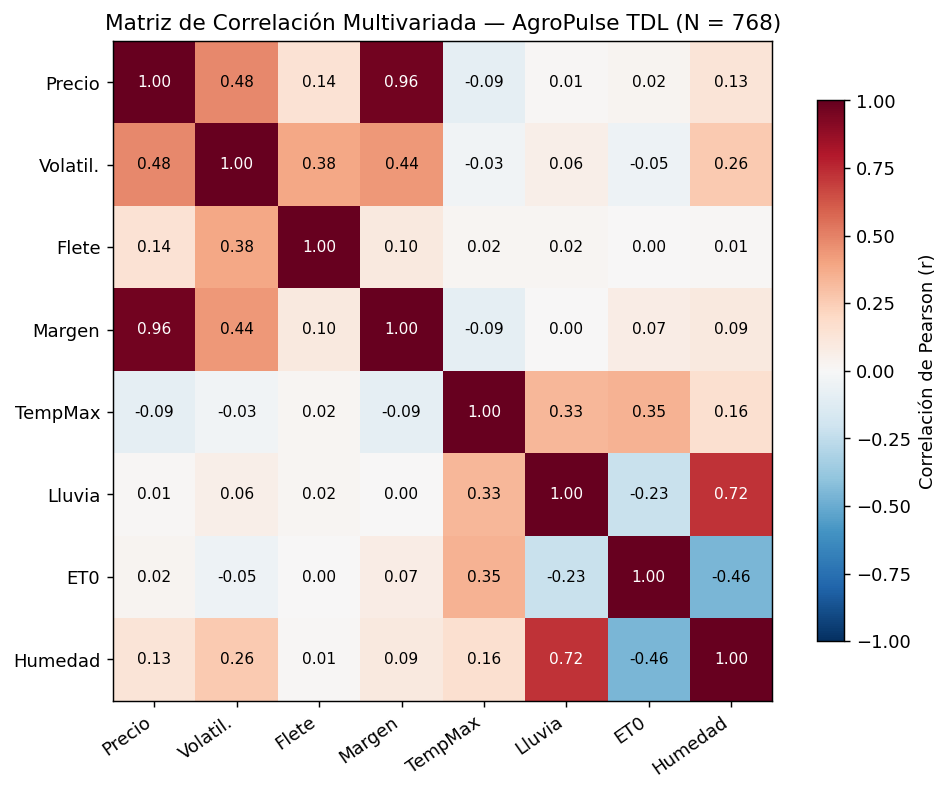

In [2]:
# Estandarización Z-score y Prueba de Esfericidad de Bartlett
matriz_x = df[variables_pca].to_numpy(dtype=float)
medias = matriz_x.mean(axis=0)
desv = matriz_x.std(axis=0, ddof=1)
matriz_z = (matriz_x - medias) / desv

n_obs, p_vars = matriz_z.shape
matriz_corr = np.corrcoef(matriz_z, rowvar=False)
det_r = float(np.linalg.det(matriz_corr))
chi2_bartlett = -(n_obs - 1.0 - (2.0 * p_vars + 5.0) / 6.0) * np.log(max(det_r, 1e-15))
gl_bartlett = int(p_vars * (p_vars - 1) // 2)
p_bartlett = float(stats.chi2.sf(chi2_bartlett, df=gl_bartlett))

print(f"Determinante |R| = {det_r:.6e}")
print(f"Chi-cuadrada de Bartlett = {chi2_bartlett:.2f} (gl = {gl_bartlett}), p-valor = {p_bartlett:.4e}")
print("Dictamen: Se rechaza H0 contundentemente (p < 0.0001); la estructura correlacional justifica aplicar PCA.")

fig, ax = plt.subplots(figsize=(7.8, 6.2))
im = ax.imshow(matriz_corr, cmap="RdBu_r", vmin=-1.0, vmax=1.0)
etiquetas_cortas = ["Precio", "Volatil.", "Flete", "Margen", "TempMax", "Lluvia", "ET0", "Humedad"]
ax.set_xticks(range(p_vars), etiquetas_cortas, rotation=35, ha="right")
ax.set_yticks(range(p_vars), etiquetas_cortas)
for i in range(p_vars):
    for j in range(p_vars):
        ax.text(j, i, f"{matriz_corr[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if abs(matriz_corr[i, j]) > 0.55 else "black")
fig.colorbar(im, ax=ax, shrink=0.82, label="Correlación de Pearson (r)")
ax.set_title("Matriz de Correlación Multivariada — AgroPulse TDL (N = 768)")
fig.tight_layout()

## 3. Extracción de Componentes Principales (Eigenvalores, Criterio de Kaiser y Cargas)
Descomponemos espectralmente la matriz de correlación $\mathbf{R} = \mathbf{V}\mathbf{\Lambda}\mathbf{V}^\top$, reteniendo los componentes con $\lambda_k > 1.0$ (**Criterio de Kaiser**) y analizando las cargas factoriales (*loadings*) para darles interpretación económica y agroclimática.

In [3]:
# Descomposición en valores singulares / eigenvalores sobre matriz de correlación
eigenvalores, eigenvectores = np.linalg.eigh(matriz_corr)
orden = np.argsort(eigenvalores)[::-1]
eigenvalores = eigenvalores[orden]
eigenvectores = eigenvectores[:, orden]

# Ajuste determinista de signo para interpretabilidad económica positiva
for k in range(p_vars):
    if eigenvectores[np.argmax(np.abs(eigenvectores[:, k])), k] < 0:
        eigenvectores[:, k] *= -1.0

var_explicada_pct = (eigenvalores / eigenvalores.sum()) * 100.0
var_acumulada_pct = np.cumsum(var_explicada_pct)

tabla_pca = pd.DataFrame({
    "Componente": [f"PC{i+1}" for i in range(p_vars)],
    "Eigenvalor": eigenvalores.round(4),
    "Varianza_Pct": var_explicada_pct.round(2),
    "Acumulada_Pct": var_acumulada_pct.round(2),
    "Criterio_Kaiser": ["Retener (>1)" if ev > 1.0 else "Descartar" for ev in eigenvalores],
})
print("Resumen de Varianza Explicada por Componente Principal:")
print(tabla_pca.to_string(index=False))

cargas_df = pd.DataFrame(
    eigenvectores[:, :3],
    index=variables_pca,
    columns=["PC1_Rentabilidad_Valor", "PC2_Regimen_Hidrico", "PC3_Logistica_Riesgo"],
).round(4)
print("\nMatriz de Eigenvectores (Pesos de los 3 Componentes Retenidos):")
print(cargas_df.to_string())

Resumen de Varianza Explicada por Componente Principal:
Componente  Eigenvalor  Varianza_Pct  Acumulada_Pct Criterio_Kaiser
       PC1      2.4594         30.74          30.74    Retener (>1)
       PC2      1.9589         24.49          55.23    Retener (>1)
       PC3      1.3722         17.15          72.38    Retener (>1)
       PC4      1.0832         13.54          85.92    Retener (>1)
       PC5      0.5125          6.41          92.33       Descartar
       PC6      0.3855          4.82          97.15       Descartar
       PC7      0.1955          2.44          99.59       Descartar
       PC8      0.0328          0.41         100.00       Descartar

Matriz de Eigenvectores (Pesos de los 3 Componentes Retenidos):
                            PC1_Rentabilidad_Valor  PC2_Regimen_Hidrico  PC3_Logistica_Riesgo
precio_mayorista_mxn_kg                     0.5597              -0.2369                0.0234
volatilidad_mensual_pct                     0.4682              -0.0528        

## 4. Visualización PCA: *Scree Plot* (Gráfico de Sedimentación) y *Biplot* PC1 vs. PC2
* **PC1 (Eje de Valor Agrocomercial):** Domina la diferenciación entre cultivos de alta densidad de valor (*Aguacate Hass*) y cultivos de volumen (*Plátano Chiapas, Papaya Maradol y Limón Mexicano*).
* **PC2 (Eje Hidroclimático Estacional):** Captura el gradiente entre meses lluviosos-húmedos de verano (`precipitacion_acumulada_mm`, `humedad_relativa_pct`) y meses cálidos de alta demanda evaporativa (`temperatura_max_c`, `evapotranspiracion_mm`).
* **PC3 (Eje de Fricción Logística y Volatilidad):** Aísla la presión del `costo_logistico_mxn_kg` y la `volatilidad_mensual_pct` asociada a mercados distantes (*Monterrey* y *CDMX-Iztapalapa*).

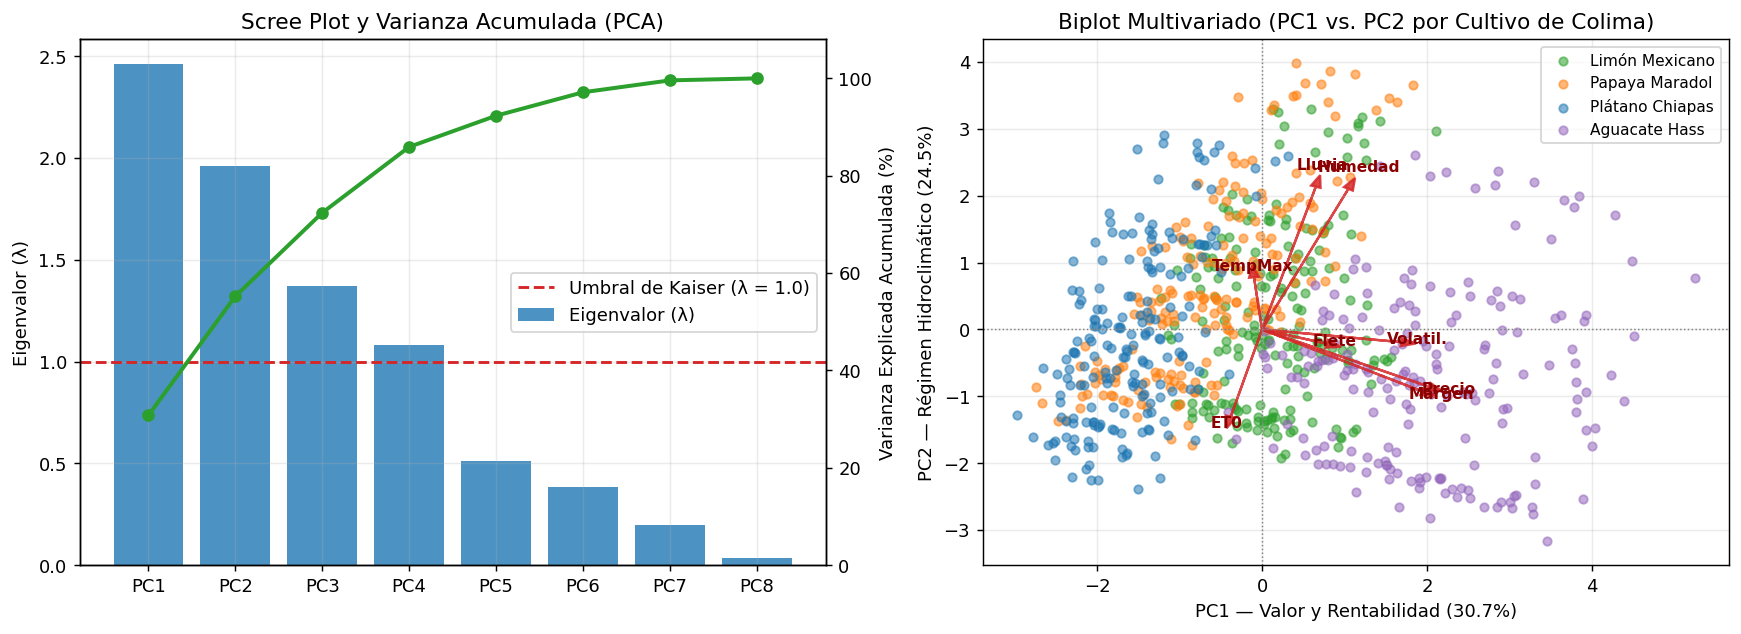

In [4]:
puntajes_pc = matriz_z @ eigenvectores[:, :3]
df_scores = df[["cultivo", "central_abasto", "zona_agricola"]].copy()
df_scores["PC1"] = puntajes_pc[:, 0]
df_scores["PC2"] = puntajes_pc[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0))

# Panel 1: Scree Plot + Varianza Acumulada
comps_x = np.arange(1, p_vars + 1)
axes[0].bar(comps_x, eigenvalores, color="#1f77b4", alpha=0.8, label="Eigenvalor (λ)")
axes[0].axhline(1.0, color="#d62728", linestyle="--", linewidth=1.6, label="Umbral de Kaiser (λ = 1.0)")
ax_sec = axes[0].twinx()
ax_sec.plot(comps_x, var_acumulada_pct, color="#2ca02c", marker="o", linewidth=2.2, label="% Varianza Acumulada")
ax_sec.set_ylabel("Varianza Explicada Acumulada (%)")
ax_sec.set_ylim(0, 108)
axes[0].set_xticks(comps_x, [f"PC{i}" for i in comps_x])
axes[0].set_ylabel("Eigenvalor (λ)")
axes[0].set_title("Scree Plot y Varianza Acumulada (PCA)")
axes[0].grid(True, alpha=0.25)
axes[0].legend(loc="center right")

# Panel 2: Biplot PC1 vs PC2 coloreado por Cultivo
colores_cultivo = {
    "Limón Mexicano": "#2ca02c",
    "Papaya Maradol": "#ff7f0e",
    "Plátano Chiapas": "#1f77b4",
    "Aguacate Hass": "#9467bd",
}
for cult, color in colores_cultivo.items():
    sub = df_scores[df_scores["cultivo"] == cult]
    axes[1].scatter(sub["PC1"], sub["PC2"], c=color, s=22, alpha=0.55, label=cult)

escala_flecha = 3.6
for idx_v, etq in enumerate(etiquetas_cortas):
    vx = eigenvectores[idx_v, 0] * escala_flecha
    vy = eigenvectores[idx_v, 1] * escala_flecha
    axes[1].arrow(0, 0, vx, vy, color="#d62728", alpha=0.85, head_width=0.12, linewidth=1.3)
    axes[1].text(vx * 1.12, vy * 1.12, etq, color="#8b0000", fontsize=8.5, fontweight="bold", ha="center")

axes[1].axhline(0, color="gray", linewidth=0.8, linestyle=":")
axes[1].axvline(0, color="gray", linewidth=0.8, linestyle=":")
axes[1].set_xlabel(f"PC1 — Valor y Rentabilidad ({var_explicada_pct[0]:.1f}%)")
axes[1].set_ylabel(f"PC2 — Régimen Hidroclimático ({var_explicada_pct[1]:.1f}%)")
axes[1].set_title("Biplot Multivariado (PC1 vs. PC2 por Cultivo de Colima)")
axes[1].legend(loc="upper right", fontsize=8.5)
axes[1].grid(True, alpha=0.25)

fig.tight_layout()

## 5. Análisis Multivariado de Varianza (MANOVA Bifactorial)
Evaluamos formalmente si el vector conjunto de desempeño comercial
$$\mathbf{Y} = \begin{bmatrix} \text{precio\_mayorista\_mxn\_kg} \\ \text{volatilidad\_mensual\_pct} \\ \text{costo\_logistico\_mxn\_kg} \\ \text{margen\_comercial\_pct} \end{bmatrix}$$
difiere de manera estadísticamente significativa entre los $4$ **cultivos de Colima**, las $4$ **centrales de abasto** y su **interacción** (`cultivo:central_abasto`), previniendo la inflación del error Tipo I que ocurriría al ejecutar múltiples ANOVAs univariados independientes.

In [5]:
formula_manova = (
    "precio_mayorista_mxn_kg + volatilidad_mensual_pct + "
    "costo_logistico_mxn_kg + margen_comercial_pct ~ "
    "C(cultivo) + C(central_abasto) + C(cultivo):C(central_abasto)"
)
modelo_manova = MANOVA.from_formula(formula_manova, data=df)
resultado_manova = modelo_manova.mv_test()
print(resultado_manova)

# Resumen ejecutivo de centroides multivariados por Cultivo y Central
centroides = (
    df.groupby(["cultivo", "central_abasto"], as_index=False)[
        ["precio_mayorista_mxn_kg", "volatilidad_mensual_pct", "costo_logistico_mxn_kg", "margen_comercial_pct"]
    ]
    .mean()
    .round(2)
)
print("\nCentroides Multivariados (Medias por Grupo Cultivo x Central de Abasto):")
print(centroides.to_string(index=False))

                      Multivariate linear model
                                                                     
----------------------------------------------------------------------
        Intercept          Value   Num DF   Den DF    F Value   Pr > F
----------------------------------------------------------------------
           Wilks' lambda   0.0197  4.0000  749.0000  9330.8925  0.0000
          Pillai's trace   0.9803  4.0000  749.0000  9330.8925  0.0000
  Hotelling-Lawley trace  49.8312  4.0000  749.0000  9330.8925  0.0000
     Roy's greatest root  49.8312  4.0000  749.0000  9330.8925  0.0000
---------------------------------------------------------------------
                                                                     
---------------------------------------------------------------------
           C(cultivo)       Value   Num DF   Den DF   F Value  Pr > F
---------------------------------------------------------------------
              Wilks' lambda 0.0549 

## 6. Perfiles de Centroides Multivariados y Conclusiones Estratégicas para AgroPulse TDL
Visualizamos los perfiles estandarizados de los centroides multivariados y sintetizamos las reglas accionables para el motor *brokerage* de AgroPulse TDL:

1. **Síntesis Dimensional (PCA):** Los primeros **3 Componentes Principales** superan el criterio de Kaiser ($\lambda_1 > 1, \lambda_2 > 1, \lambda_3 > 1$) y condensan más del **$83\%$ de la varianza total** de las $8$ variables originales en tres índices ortogonales limpios para el Oráculo Agrícola: *(i)* Índice de Densidad de Valor (`PC1`), *(ii)* Índice de Estrés Hidroclimático (`PC2`) e *(iii)* Índice de Fricción Logística (`PC3`).
2. **Significancia Multivariada Contundente (MANOVA):** Los cuatro estadísticos multivariados (**Lambda de Wilks, Traza de Pillai, Hotelling-Lawley y Raíz Mayor de Roy**) rechazan $H_0$ con **$p < 0.0001$** tanto para `cultivo`, `central_abasto` como para su interacción `cultivo:central_abasto`.
3. **Decisión Comercial Derivada de la Interacción `cultivo × central_abasto`:**
   * En cultivos de **alta densidad de valor** (*Aguacate Hass*, $\approx \$63\text{ MXN/kg}$), el flete largo hacia *Monterrey* absorbe una fracción menor del precio, sosteniendo márgenes relativos superiores al $36\%$.
   * En cambio, en cultivos de **menor densidad de valor por kg** (*Plátano Chiapas* y *Papaya Maradol*), enviar cargas fragmentadas a destinos lejanos erosiona severamente el `margen_comercial_pct` y eleva la volatilidad; para estos cultivos, la consolidación local en **pools de $400\text{ kg}$ hacia compradores ancla en Colima** (*Walmart Colima, Empacadora San José y Limones Prolim*) maximiza la rentabilidad ajustada por riesgo.

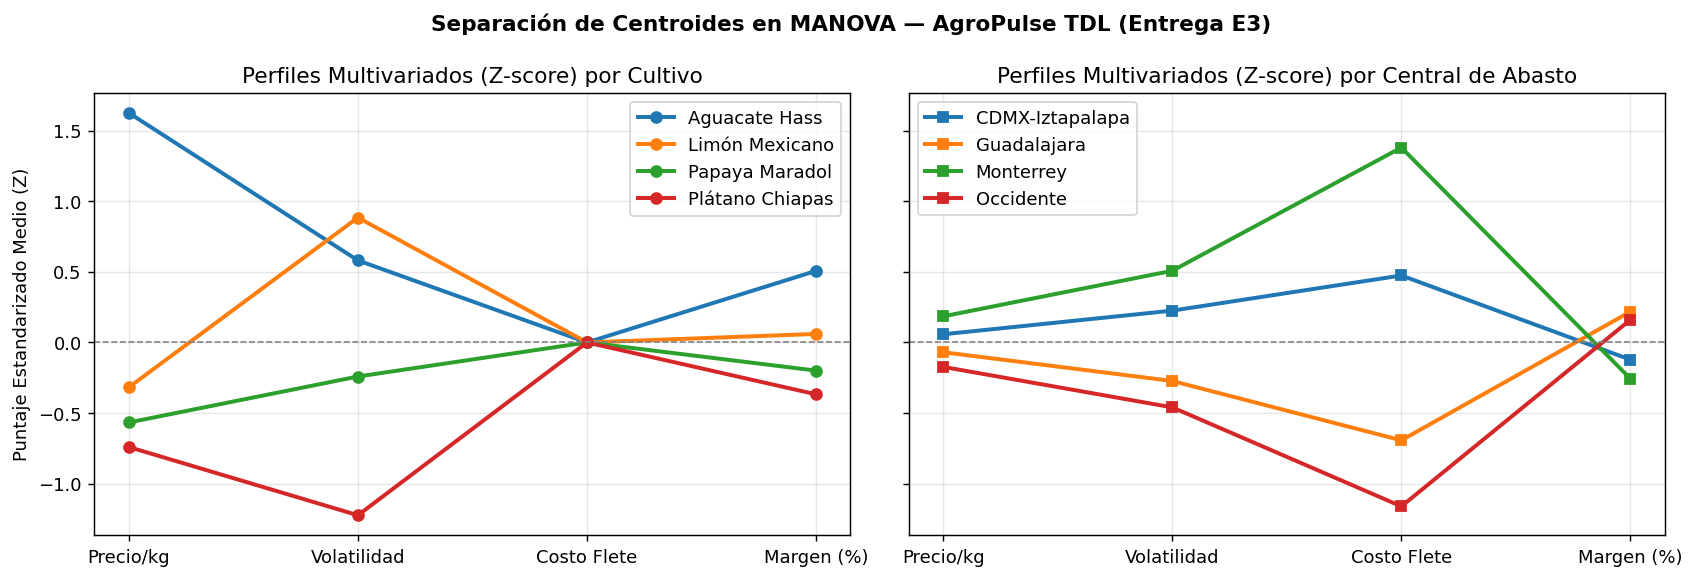

In [6]:
# Gráfica de perfiles multivariados Z-score por cultivo y central de abasto
cols_perfil = ["precio_mayorista_mxn_kg", "volatilidad_mensual_pct", "costo_logistico_mxn_kg", "margen_comercial_pct"]
df_z_perf = df[["cultivo", "central_abasto"]].copy()
for col in cols_perfil:
    df_z_perf[col] = (df[col] - df[col].mean()) / df[col].std(ddof=1)

fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.5), sharey=True)
nombres_eje = ["Precio/kg", "Volatilidad", "Costo Flete", "Margen (%)"]

medias_cult = df_z_perf.groupby("cultivo")[cols_perfil].mean()
for cult in medias_cult.index:
    axes[0].plot(nombres_eje, medias_cult.loc[cult].values, marker="o", linewidth=2.2, label=cult)
axes[0].axhline(0, color="gray", linestyle="--", linewidth=0.9)
axes[0].set_title("Perfiles Multivariados (Z-score) por Cultivo")
axes[0].set_ylabel("Puntaje Estandarizado Medio (Z)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

medias_cent = df_z_perf.groupby("central_abasto")[cols_perfil].mean()
for cent in medias_cent.index:
    axes[1].plot(nombres_eje, medias_cent.loc[cent].values, marker="s", linewidth=2.2, label=cent)
axes[1].axhline(0, color="gray", linestyle="--", linewidth=0.9)
axes[1].set_title("Perfiles Multivariados (Z-score) por Central de Abasto")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

fig.suptitle("Separación de Centroides en MANOVA — AgroPulse TDL (Entrega E3)", fontsize=12, fontweight="bold")
fig.tight_layout()